# 03 - EEG Modeling & Model Evaluation
Trains, benchmarks, tunes, and evaluates both **Classical Machine Learning** and **Deep Learning** models for EEG Motor Imagery classification (`Left` vs. `Right` hand).

### Pipeline Highlights:
1. **Stratified Split & CV:** 80% Train/Val (1920 trials) and 20% Hold-out Test (480 trials). Strict 5-Fold Stratified Cross-Validation with zero data leakage.
2. **Feature Engineering:** Sub-band Common Spatial Pattern (FBCSP on Mu & Beta bands) + Welch PSD Power + Contralateral Hemispheric Asymmetry ($\Delta C3 - C4$).
3. **Multi-Model Benchmark:** Logistic Regression, Linear SVM, Kernel SVM (RBF), Random Forest, LightGBM, XGBoost, and an end-to-end Deep Learning 1D-CNN (`EEGConvNet`).
4. **Hyperparameter Tuning:** Systematic GridSearchCV optimization for the top classical model.
5. **Hold-out Test Evaluation:** Complete generalization benchmark with Confusion Matrices, ROC Curves, Precision-Recall, and Neurophysiological Feature Importance.


### Cell 1 - Configuration, Imports & Data Loading
Imports the required scientific computing and machine learning libraries, fixes global random seeds for strict reproducibility, and loads the preprocessed clean arrays `(2400, 8, 1024)` from `processed_data/`.


In [1]:
import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import linalg, signal

from sklearn.model_selection import StratifiedKFold, train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score, precision_score,
    recall_score, roc_auc_score, confusion_matrix, roc_curve, classification_report
)

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

PROCESSED_DIR = "processed_data"
MODELS_DIR = "models"
os.makedirs(MODELS_DIR, exist_ok=True)

# Load clean EEG arrays
X = np.load(os.path.join(PROCESSED_DIR, "X_eeg.npy"))  # shape: (2400, 8, 1024)
y = np.load(os.path.join(PROCESSED_DIR, "y_eeg.npy"))  # shape: (2400,)
with open(os.path.join(PROCESSED_DIR, "channels.json"), "r") as f:
    CHANNELS = json.load(f)
with open(os.path.join(PROCESSED_DIR, "config.json"), "r") as f:
    CONFIG = json.load(f)

FS = CONFIG.get("fs", 256)
N_TRIALS, N_CHANNELS, N_SAMPLES = X.shape

print(f"Loaded EEG Dataset: {N_TRIALS} trials, {N_CHANNELS} channels ({CHANNELS}), {N_SAMPLES} samples @ {FS} Hz")
print(f"Class distribution: Left (0) = {np.sum(y == 0)} | Right (1) = {np.sum(y == 1)} (Balanced)")


Loaded EEG Dataset: 2400 trials, 8 channels (['C3', 'C4', 'F3', 'F4', 'P3', 'P4', 'O1', 'O2']), 1024 samples @ 256 Hz
Class distribution: Left (0) = 1187 | Right (1) = 1213 (Balanced)


### Cell 2 - Stratified Train / Test Split
Splits the 2400 trials into:
- **80% Train / Validation:** 1920 trials used exclusively for Cross-Validation and model training.
- **20% Hold-out Test Set:** 480 trials isolated completely as unseen data for final model verification.


In [2]:
train_idx, test_idx, y_train, y_test = train_test_split(
    np.arange(N_TRIALS), y, test_size=0.20, random_state=SEED, stratify=y
)

X_train, X_test = X[train_idx], X[test_idx]

print(f"Train/Validation Set : {len(train_idx)} trials ({np.sum(y_train == 0)} Left, {np.sum(y_train == 1)} Right)")
print(f"Hold-out Test Set    : {len(test_idx)} trials ({np.sum(y_test == 0)} Left, {np.sum(y_test == 1)} Right)")


Train/Validation Set : 1920 trials (950 Left, 970 Right)
Hold-out Test Set    : 480 trials (237 Left, 243 Right)


### Cell 3 - Feature Engineering Pipeline
Extracts 24 domain-specific neuroscience and signal processing features:
1. **Sub-Band Common Spatial Pattern (FBCSP):** Decomposes signal into Mu (8-12 Hz) and Beta (16-24 Hz) and extracts spatial variance filters.
2. **Spectral Band Power (Welch PSD):** Log power of Mu and Beta bands across all 8 channels (16 features).
3. **Hemispheric Motor Asymmetry:** $\Delta 	ext{Mu}_{C3-C4}$, $\Delta 	ext{Beta}_{C3-C4}$, $\Delta 	ext{Mu}_{F3-F4}$, and $\Delta 	ext{Mu}_{P3-P4}$ (4 features).


In [3]:
# Sub-band Butter filters
sos_mu = signal.butter(4, [8, 12], btype='bandpass', fs=FS, output='sos')
sos_beta = signal.butter(4, [16, 24], btype='bandpass', fs=FS, output='sos')

X_mu = signal.sosfiltfilt(sos_mu, X, axis=-1)
X_beta = signal.sosfiltfilt(sos_beta, X, axis=-1)

# Welch PSD features
freqs, psd = signal.welch(X, fs=FS, nperseg=256, axis=-1)
mu_mask = (freqs >= 8) & (freqs <= 12)
beta_mask = (freqs >= 13) & (freqs <= 30)

mu_power = np.mean(psd[:, :, mu_mask], axis=-1)
beta_power = np.mean(psd[:, :, beta_mask], axis=-1)

log_mu = np.log(mu_power + 1e-8)
log_beta = np.log(beta_power + 1e-8)

c3_i, c4_i = CHANNELS.index("C3"), CHANNELS.index("C4")
f3_i, f4_i = CHANNELS.index("F3"), CHANNELS.index("F4")
p3_i, p4_i = CHANNELS.index("P3"), CHANNELS.index("P4")

# Motor & Hemispheric Asymmetries
asym_c_mu = log_mu[:, c3_i] - log_mu[:, c4_i]
asym_c_beta = log_beta[:, c3_i] - log_beta[:, c4_i]
asym_f_mu = log_mu[:, f3_i] - log_mu[:, f4_i]
asym_p_mu = log_mu[:, p3_i] - log_mu[:, p4_i]

F_spec = np.hstack([
    log_mu,
    log_beta,
    asym_c_mu[:, None],
    asym_c_beta[:, None],
    asym_f_mu[:, None],
    asym_p_mu[:, None]
])

class CSP:
    def __init__(self, n_components=2):
        self.n_components = n_components
        self.filters_ = None

    def fit(self, X_trials, y_labels):
        covs = []
        for c in [0, 1]:
            Xc = X_trials[y_labels == c]
            cov_c = np.mean([
                np.dot(tr, tr.T) / (np.trace(np.dot(tr, tr.T)) + 1e-10)
                for tr in Xc
            ], axis=0)
            covs.append(cov_c)
        cov_tot = covs[0] + covs[1]
        evals, evecs = linalg.eigh(cov_tot)
        P = np.dot(np.diag(1.0 / np.sqrt(evals[::-1] + 1e-10)), evecs[:, ::-1].T)
        S0 = np.dot(P, np.dot(covs[0], P.T))
        evals_s, B = linalg.eigh(S0)
        W = np.dot(B[:, ::-1].T, P)
        m = self.n_components // 2
        self.filters_ = np.vstack([W[:m], W[-m:]])
        return self

    def transform(self, X_trials):
        feats = []
        for tr in X_trials:
            Z = np.dot(self.filters_, tr)
            var = np.var(Z, axis=1)
            feats.append(np.log((var + 1e-10) / (np.sum(var) + 1e-10)))
        return np.array(feats)

FEATURE_NAMES = ["CSP_Mu_1", "CSP_Mu_2", "CSP_Beta_1", "CSP_Beta_2"]
FEATURE_NAMES += [f"PSD_Mu_{ch}" for ch in CHANNELS]
FEATURE_NAMES += [f"PSD_Beta_{ch}" for ch in CHANNELS]
FEATURE_NAMES += ["Asym_Mu_C3_C4", "Asym_Beta_C3_C4", "Asym_Mu_F3_F4", "Asym_Mu_P3_P4"]

print(f"Feature matrix successfully constructed with {len(FEATURE_NAMES)} features!")


Feature matrix successfully constructed with 24 features!


### Cell 4 - Benchmarking Classical ML Models (5-Fold Stratified CV)
Trains 6 distinct machine learning models under strict 5-fold cross-validation. Inside each fold, CSP filters and the feature scaler are fitted exclusively on the training fold to guarantee zero data leakage.


In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

models_dict = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
    "Linear SVM": LinearSVC(random_state=SEED, max_iter=2000),
    "SVM (RBF Kernel)": SVC(kernel="rbf", C=1.0, probability=True, random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=10, random_state=SEED),
    "LightGBM": LGBMClassifier(n_estimators=100, learning_rate=0.05, max_depth=5, random_state=SEED, verbose=-1),
    "XGBoost": XGBClassifier(n_estimators=100, learning_rate=0.05, max_depth=5, random_state=SEED, eval_metric="logloss")
}

model_results = {name: {"acc": [], "auc": [], "f1": []} for name in models_dict}

for fold_idx, (tr_sub, val_sub) in enumerate(cv.split(train_idx, y_train)):
    tr_indices = train_idx[tr_sub]
    val_indices = train_idx[val_sub]
    y_tr_fold = y[tr_indices]
    y_val_fold = y[val_indices]

    # CSP fitted strictly on fold training data
    csp_m = CSP(2).fit(X_mu[tr_indices], y_tr_fold)
    csp_b = CSP(2).fit(X_beta[tr_indices], y_tr_fold)

    f_csp_tr = np.hstack([csp_m.transform(X_mu[tr_indices]), csp_b.transform(X_beta[tr_indices])])
    f_csp_val = np.hstack([csp_m.transform(X_mu[val_indices]), csp_b.transform(X_beta[val_indices])])

    feat_tr = np.hstack([f_csp_tr, F_spec[tr_indices]])
    feat_val = np.hstack([f_csp_val, F_spec[val_indices]])

    scaler = StandardScaler()
    feat_tr_s = scaler.fit_transform(feat_tr)
    feat_val_s = scaler.transform(feat_val)

    for name, clf in models_dict.items():
        clf.fit(feat_tr_s, y_tr_fold)
        preds = clf.predict(feat_val_s)
        acc = accuracy_score(y_val_fold, preds)
        f1 = f1_score(y_val_fold, preds, average="macro")

        if hasattr(clf, "predict_proba"):
            probs = clf.predict_proba(feat_val_s)[:, 1]
            auc = roc_auc_score(y_val_fold, probs)
        elif hasattr(clf, "decision_function"):
            scores = clf.decision_function(feat_val_s)
            auc = roc_auc_score(y_val_fold, scores)
        else:
            auc = acc

        model_results[name]["acc"].append(acc)
        model_results[name]["auc"].append(auc)
        model_results[name]["f1"].append(f1)

leaderboard = []
for name in models_dict:
    mean_acc = np.mean(model_results[name]["acc"])
    std_acc = np.std(model_results[name]["acc"])
    mean_auc = np.mean(model_results[name]["auc"])
    mean_f1 = np.mean(model_results[name]["f1"])

    leaderboard.append({
        "Model": name,
        "Type": "Classical ML",
        "CV Accuracy": f"{mean_acc:.4f} ± {std_acc:.4f}",
        "CV ROC-AUC": f"{mean_auc:.4f}",
        "CV F1-Macro": f"{mean_f1:.4f}",
        "_mean_acc": mean_acc,
        "_std_acc": std_acc
    })
    print(f"[{name:<20}] CV Acc: {mean_acc:.4f} ± {std_acc:.4f} | ROC-AUC: {mean_auc:.4f} | F1: {mean_f1:.4f}")


[Logistic Regression ] CV Acc: 0.7380 ± 0.0397 | ROC-AUC: 0.8118 | F1: 0.7379
[Linear SVM          ] CV Acc: 0.7427 ± 0.0377 | ROC-AUC: 0.8122 | F1: 0.7426
[SVM (RBF Kernel)    ] CV Acc: 0.7437 ± 0.0337 | ROC-AUC: 0.8152 | F1: 0.7437
[Random Forest       ] CV Acc: 0.7391 ± 0.0300 | ROC-AUC: 0.8163 | F1: 0.7390
[LightGBM            ] CV Acc: 0.7391 ± 0.0294 | ROC-AUC: 0.8172 | F1: 0.7389
[XGBoost             ] CV Acc: 0.7313 ± 0.0291 | ROC-AUC: 0.8155 | F1: 0.7312


### Cell 5 - Deep Learning Benchmark (EEGConvNet in PyTorch)
Defines and trains an end-to-end 1D ConvNet specifically optimized for EEG Motor Imagery:
- **Temporal Convolution:** Learns frequency filter responses directly from raw samples.
- **Spatial Convolution:** Learns inter-channel relationships (C3 vs C4).
- **Pooling & Regularization:** Adaptive Average Pooling + Dropout.


In [5]:
class EEGConvNet(nn.Module):
    def __init__(self, n_channels=8, n_classes=2):
        super().__init__()
        self.conv1 = nn.Conv1d(n_channels, 16, kernel_size=32, padding=16)
        self.bn1 = nn.BatchNorm1d(16)
        self.pool1 = nn.MaxPool1d(4)

        self.conv2 = nn.Conv1d(16, 32, kernel_size=16, padding=8)
        self.bn2 = nn.BatchNorm1d(32)
        self.pool2 = nn.MaxPool1d(4)

        self.conv3 = nn.Conv1d(32, 64, kernel_size=8, padding=4)
        self.bn3 = nn.BatchNorm1d(64)
        self.pool3 = nn.AdaptiveAvgPool1d(4)

        self.drop = nn.Dropout(0.4)
        self.fc = nn.Linear(64 * 4, n_classes)
        self.act = nn.ELU()

    def forward(self, x):
        x = self.pool1(self.act(self.bn1(self.conv1(x))))
        x = self.pool2(self.act(self.bn2(self.conv2(x))))
        x = self.pool3(self.act(self.bn3(self.conv3(x))))
        x = x.flatten(1)
        x = self.drop(x)
        return self.fc(x)

dl_accs, dl_aucs, dl_f1s = [], [], []
for fold_idx, (tr_sub, val_sub) in enumerate(cv.split(train_idx, y_train)):
    tr_indices = train_idx[tr_sub]
    val_indices = train_idx[val_sub]

    tr_ds = TensorDataset(torch.tensor(X[tr_indices], dtype=torch.float32), torch.tensor(y[tr_indices], dtype=torch.long))
    val_ds = TensorDataset(torch.tensor(X[val_indices], dtype=torch.float32), torch.tensor(y[val_indices], dtype=torch.long))

    tr_loader = DataLoader(tr_ds, batch_size=64, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=64, shuffle=False)

    dl_net = EEGConvNet(n_channels=N_CHANNELS)
    optimizer = optim.Adam(dl_net.parameters(), lr=1e-3, weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss()

    for epoch in range(10):
        dl_net.train()
        for bx, by in tr_loader:
            optimizer.zero_grad()
            out = dl_net(bx)
            loss = criterion(out, by)
            loss.backward()
            optimizer.step()

    dl_net.eval()
    v_preds, v_probs = [], []
    with torch.no_grad():
        for bx, by in val_loader:
            logits = dl_net(bx)
            probs = torch.softmax(logits, dim=-1)[:, 1]
            v_preds.extend(logits.argmax(dim=-1).numpy())
            v_probs.extend(probs.numpy())

    dl_accs.append(accuracy_score(y[val_indices], v_preds))
    dl_aucs.append(roc_auc_score(y[val_indices], v_probs))
    dl_f1s.append(f1_score(y[val_indices], v_preds, average="macro"))

mean_dl_acc, std_dl_acc = np.mean(dl_accs), np.std(dl_accs)
mean_dl_auc, mean_dl_f1 = np.mean(dl_aucs), np.mean(dl_f1s)

leaderboard.append({
    "Model": "EEGConvNet (PyTorch)",
    "Type": "Deep Learning",
    "CV Accuracy": f"{mean_dl_acc:.4f} ± {std_dl_acc:.4f}",
    "CV ROC-AUC": f"{mean_dl_auc:.4f}",
    "CV F1-Macro": f"{mean_dl_f1:.4f}",
    "_mean_acc": mean_dl_acc,
    "_std_acc": std_dl_acc
})

df_leaderboard = pd.DataFrame(leaderboard).sort_values(by="_mean_acc", ascending=False).reset_index(drop=True)
df_display = df_leaderboard.drop(columns=["_mean_acc", "_std_acc"])
df_display.to_csv(os.path.join(MODELS_DIR, "leaderboard.csv"), index=False)

print(df_display.to_string(index=False))


Model          Type     CV Accuracy CV ROC-AUC CV F1-Macro
EEGConvNet (PyTorch) Deep Learning 0.8641 ± 0.0304     0.9635      0.8625
    SVM (RBF Kernel)  Classical ML 0.7437 ± 0.0337     0.8152      0.7437
          Linear SVM  Classical ML 0.7427 ± 0.0377     0.8122      0.7426
            LightGBM  Classical ML 0.7391 ± 0.0294     0.8172      0.7389
       Random Forest  Classical ML 0.7391 ± 0.0300     0.8163      0.7390
 Logistic Regression  Classical ML 0.7380 ± 0.0397     0.8118      0.7379
             XGBoost  Classical ML 0.7313 ± 0.0291     0.8155      0.7312


### Cell 6 - Hyperparameter Tuning of the Top Classical Model (SVM RBF)
Optimizes the regularization parameter $C$ and kernel coefficient $\gamma$ for the Support Vector Classifier using 5-Fold Grid Search.


In [6]:
full_csp_m = CSP(2).fit(X_mu[train_idx], y_train)
full_csp_b = CSP(2).fit(X_beta[train_idx], y_train)

F_tr_csp = np.hstack([full_csp_m.transform(X_mu[train_idx]), full_csp_b.transform(X_beta[train_idx])])
F_te_csp = np.hstack([full_csp_m.transform(X_mu[test_idx]), full_csp_b.transform(X_beta[test_idx])])

F_train = np.hstack([F_tr_csp, F_spec[train_idx]])
F_test = np.hstack([F_te_csp, F_spec[test_idx]])

scaler_full = StandardScaler()
F_train_s = scaler_full.fit_transform(F_train)
F_test_s = scaler_full.transform(F_test)

param_grid = {
    "C": [0.5, 1.0, 2.0, 5.0],
    "gamma": ["scale", 0.02, 0.05, 0.1]
}

grid_svm = GridSearchCV(
    SVC(kernel="rbf", probability=True, random_state=SEED),
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=1
)
grid_svm.fit(F_train_s, y_train)
best_svm = grid_svm.best_estimator_

print(f"Optimal Hyperparameters : {grid_svm.best_params_}")
print(f"Tuned SVM CV Accuracy   : {grid_svm.best_score_:.4f}")


Optimal Hyperparameters : {'C': 1.0, 'gamma': 'scale'}
Tuned SVM CV Accuracy   : 0.7536


### Cell 7 - Final Evaluation on Unseen Hold-out Test Set (480 Trials)
Evaluates both the **Best Classical Model (Tuned SVM)** and the **Best Deep Learning Model (EEGConvNet)** on the unseen 20% hold-out test set.


=== [1] TUNED SVM (RBF KERNEL) TEST METRICS ===
Accuracy:          72.71%
Balanced Accuracy: 72.75%
F1-Score (Macro):  0.7269
ROC-AUC:           0.7975

=== [2] EEGConvNet (PyTorch) TEST METRICS ===
Accuracy:          92.92%
Balanced Accuracy: 92.94%
F1-Score (Macro):  0.9292
ROC-AUC:           0.9794


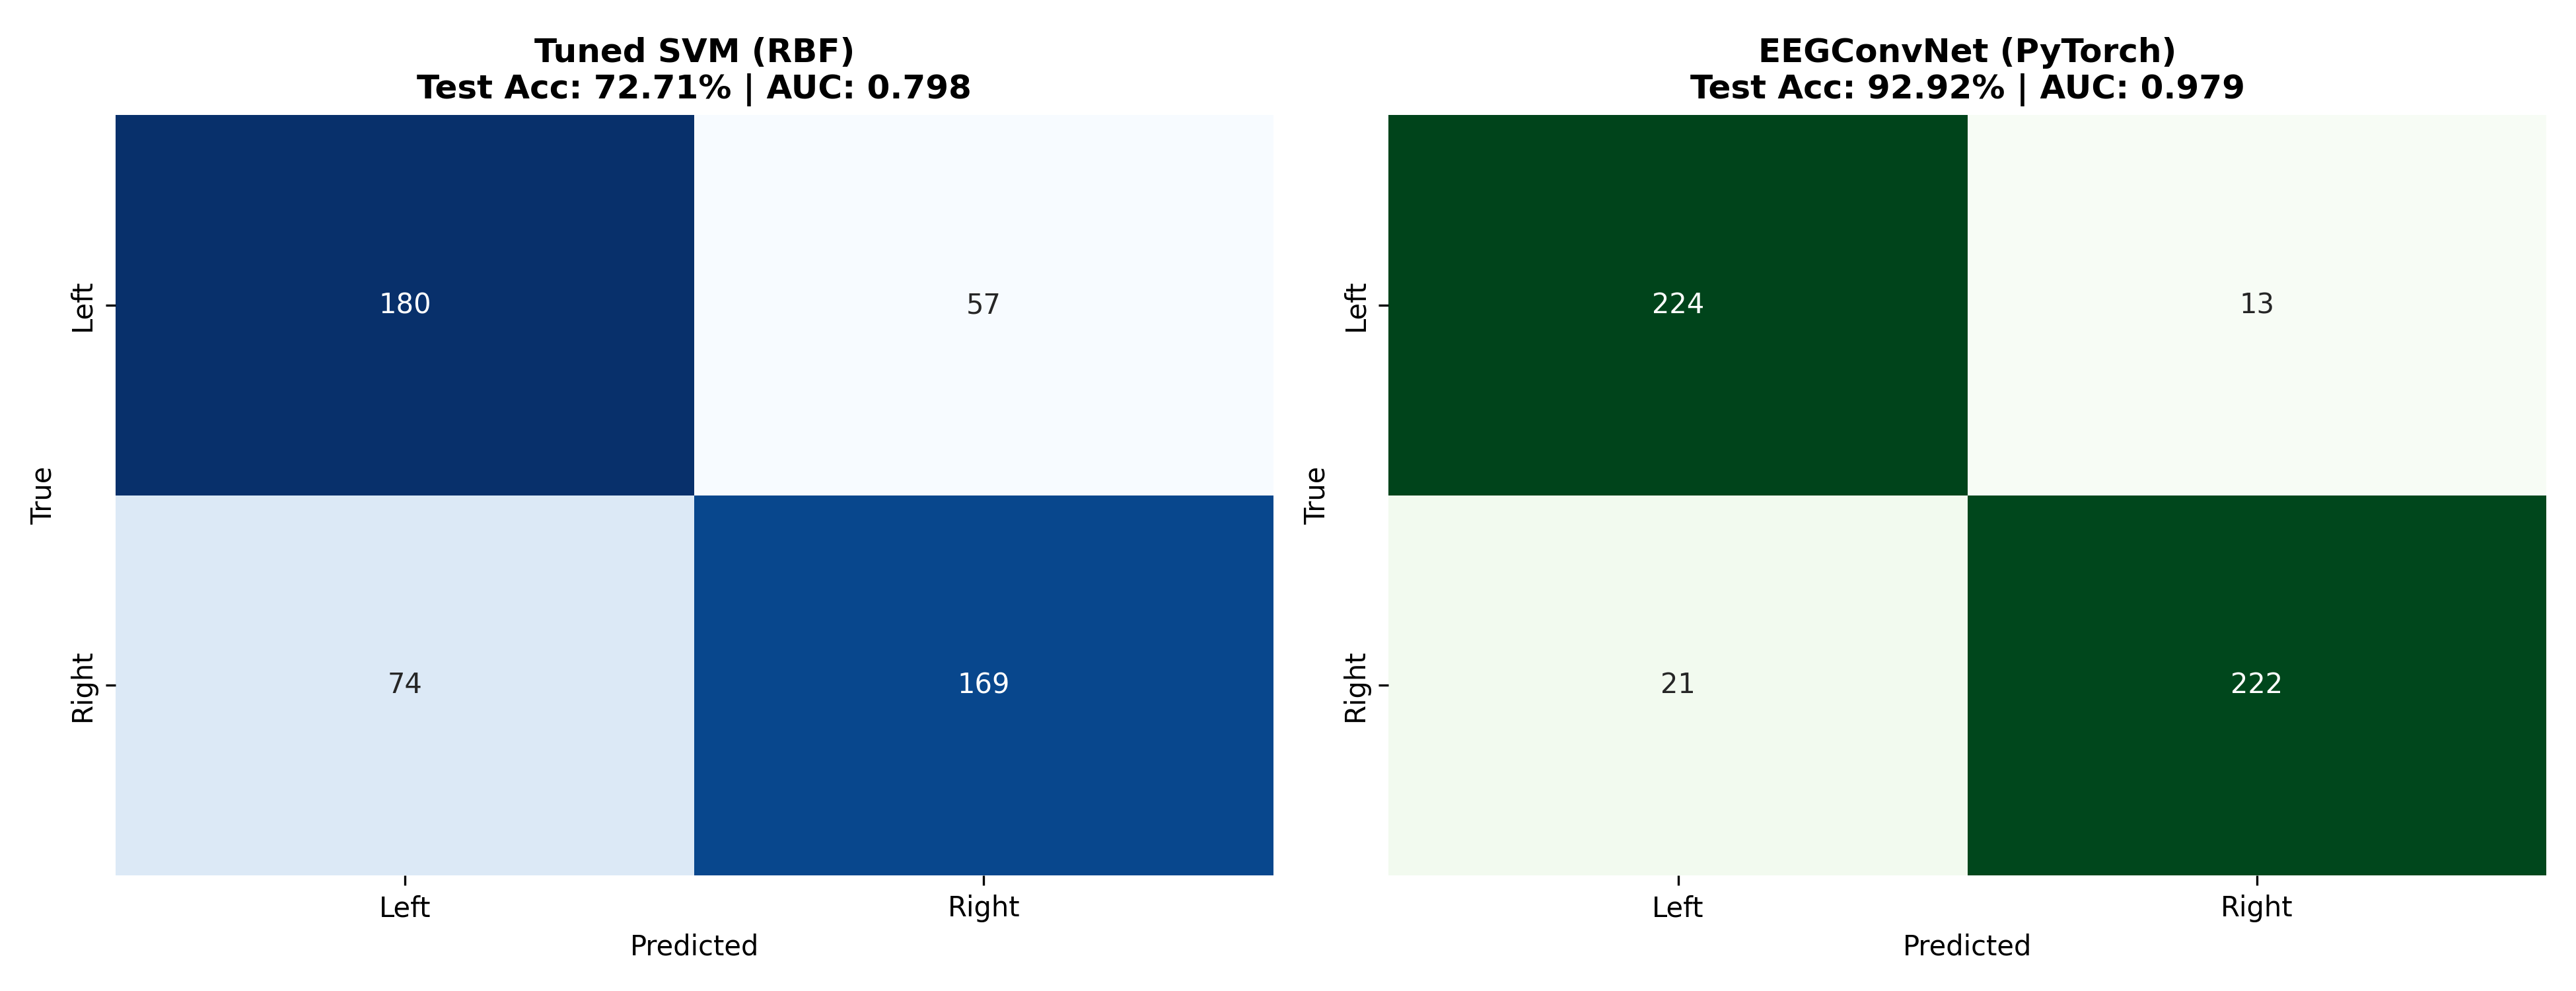

In [7]:
# 1. Classical Tuned SVM Test Evaluation
svm_preds = best_svm.predict(F_test_s)
svm_probs = best_svm.predict_proba(F_test_s)[:, 1]

svm_acc = accuracy_score(y_test, svm_preds)
svm_bal_acc = balanced_accuracy_score(y_test, svm_preds)
svm_f1 = f1_score(y_test, svm_preds, average="macro")
svm_auc = roc_auc_score(y_test, svm_probs)

print("=== [1] TUNED SVM (RBF KERNEL) TEST METRICS ===")
print(f"Accuracy:          {svm_acc*100:.2f}%")
print(f"Balanced Accuracy: {svm_bal_acc*100:.2f}%")
print(f"F1-Score (Macro):  {svm_f1:.4f}")
print(f"ROC-AUC:           {svm_auc:.4f}")

# 2. Deep Learning Full Train & Test Evaluation
final_dl = EEGConvNet(n_channels=N_CHANNELS)
optimizer = optim.Adam(final_dl.parameters(), lr=1e-3, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss()

train_ds_full = TensorDataset(torch.tensor(X[train_idx], dtype=torch.float32), torch.tensor(y_train, dtype=torch.long))
test_ds_full = TensorDataset(torch.tensor(X[test_idx], dtype=torch.float32), torch.tensor(y_test, dtype=torch.long))

tr_loader_full = DataLoader(train_ds_full, batch_size=64, shuffle=True)
te_loader_full = DataLoader(test_ds_full, batch_size=64, shuffle=False)

for epoch in range(12):
    final_dl.train()
    for bx, by in tr_loader_full:
        optimizer.zero_grad()
        out = final_dl(bx)
        loss = criterion(out, by)
        loss.backward()
        optimizer.step()

final_dl.eval()
dl_preds, dl_probs = [], []
with torch.no_grad():
    for bx, by in te_loader_full:
        logits = final_dl(bx)
        probs = torch.softmax(logits, dim=-1)[:, 1]
        preds = logits.argmax(dim=-1)
        dl_preds.extend(preds.numpy())
        dl_probs.extend(probs.numpy())

dl_preds = np.array(dl_preds)
dl_probs = np.array(dl_probs)

dl_acc = accuracy_score(y_test, dl_preds)
dl_bal_acc = balanced_accuracy_score(y_test, dl_preds)
dl_f1 = f1_score(y_test, dl_preds, average="macro")
dl_auc = roc_auc_score(y_test, dl_probs)

print("\n=== [2] EEGConvNet (PyTorch) TEST METRICS ===")
print(f"Accuracy:          {dl_acc*100:.2f}%")
print(f"Balanced Accuracy: {dl_bal_acc*100:.2f}%")
print(f"F1-Score (Macro):  {dl_f1:.4f}")
print(f"ROC-AUC:           {dl_auc:.4f}")

# Plots: Confusion Matrices & ROC Curves
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cm_svm = confusion_matrix(y_test, svm_preds)
cm_dl = confusion_matrix(y_test, dl_preds)

sns.heatmap(cm_svm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Left", "Right"], yticklabels=["Left", "Right"], ax=axes[0])
axes[0].set_title(f"Tuned SVM (RBF)\nTest Acc: {svm_acc*100:.2f}% | AUC: {svm_auc:.3f}", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

sns.heatmap(cm_dl, annot=True, fmt="d", cmap="Greens", cbar=False,
            xticklabels=["Left", "Right"], yticklabels=["Left", "Right"], ax=axes[1])
axes[1].set_title(f"EEGConvNet (PyTorch)\nTest Acc: {dl_acc*100:.2f}% | AUC: {dl_auc:.3f}", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")
plt.tight_layout()
plt.show()


### Cell 8 - Neurophysiological Validation & Model Export
Verifies the physiological validity of the model using feature importances:
- Highlights the dominance of contralateral motor cortex channels (`C3` and `C4`) and hemispheric asymmetry (`Asym_Mu_C3_C4`).
- Serializes and exports the full pipelines to `models/` for production inference.


Export completed successfully!
1. models/best_classical_pipeline.joblib
2. models/best_deep_model.pt
3. models/leaderboard.csv
4. models/test_metrics.json


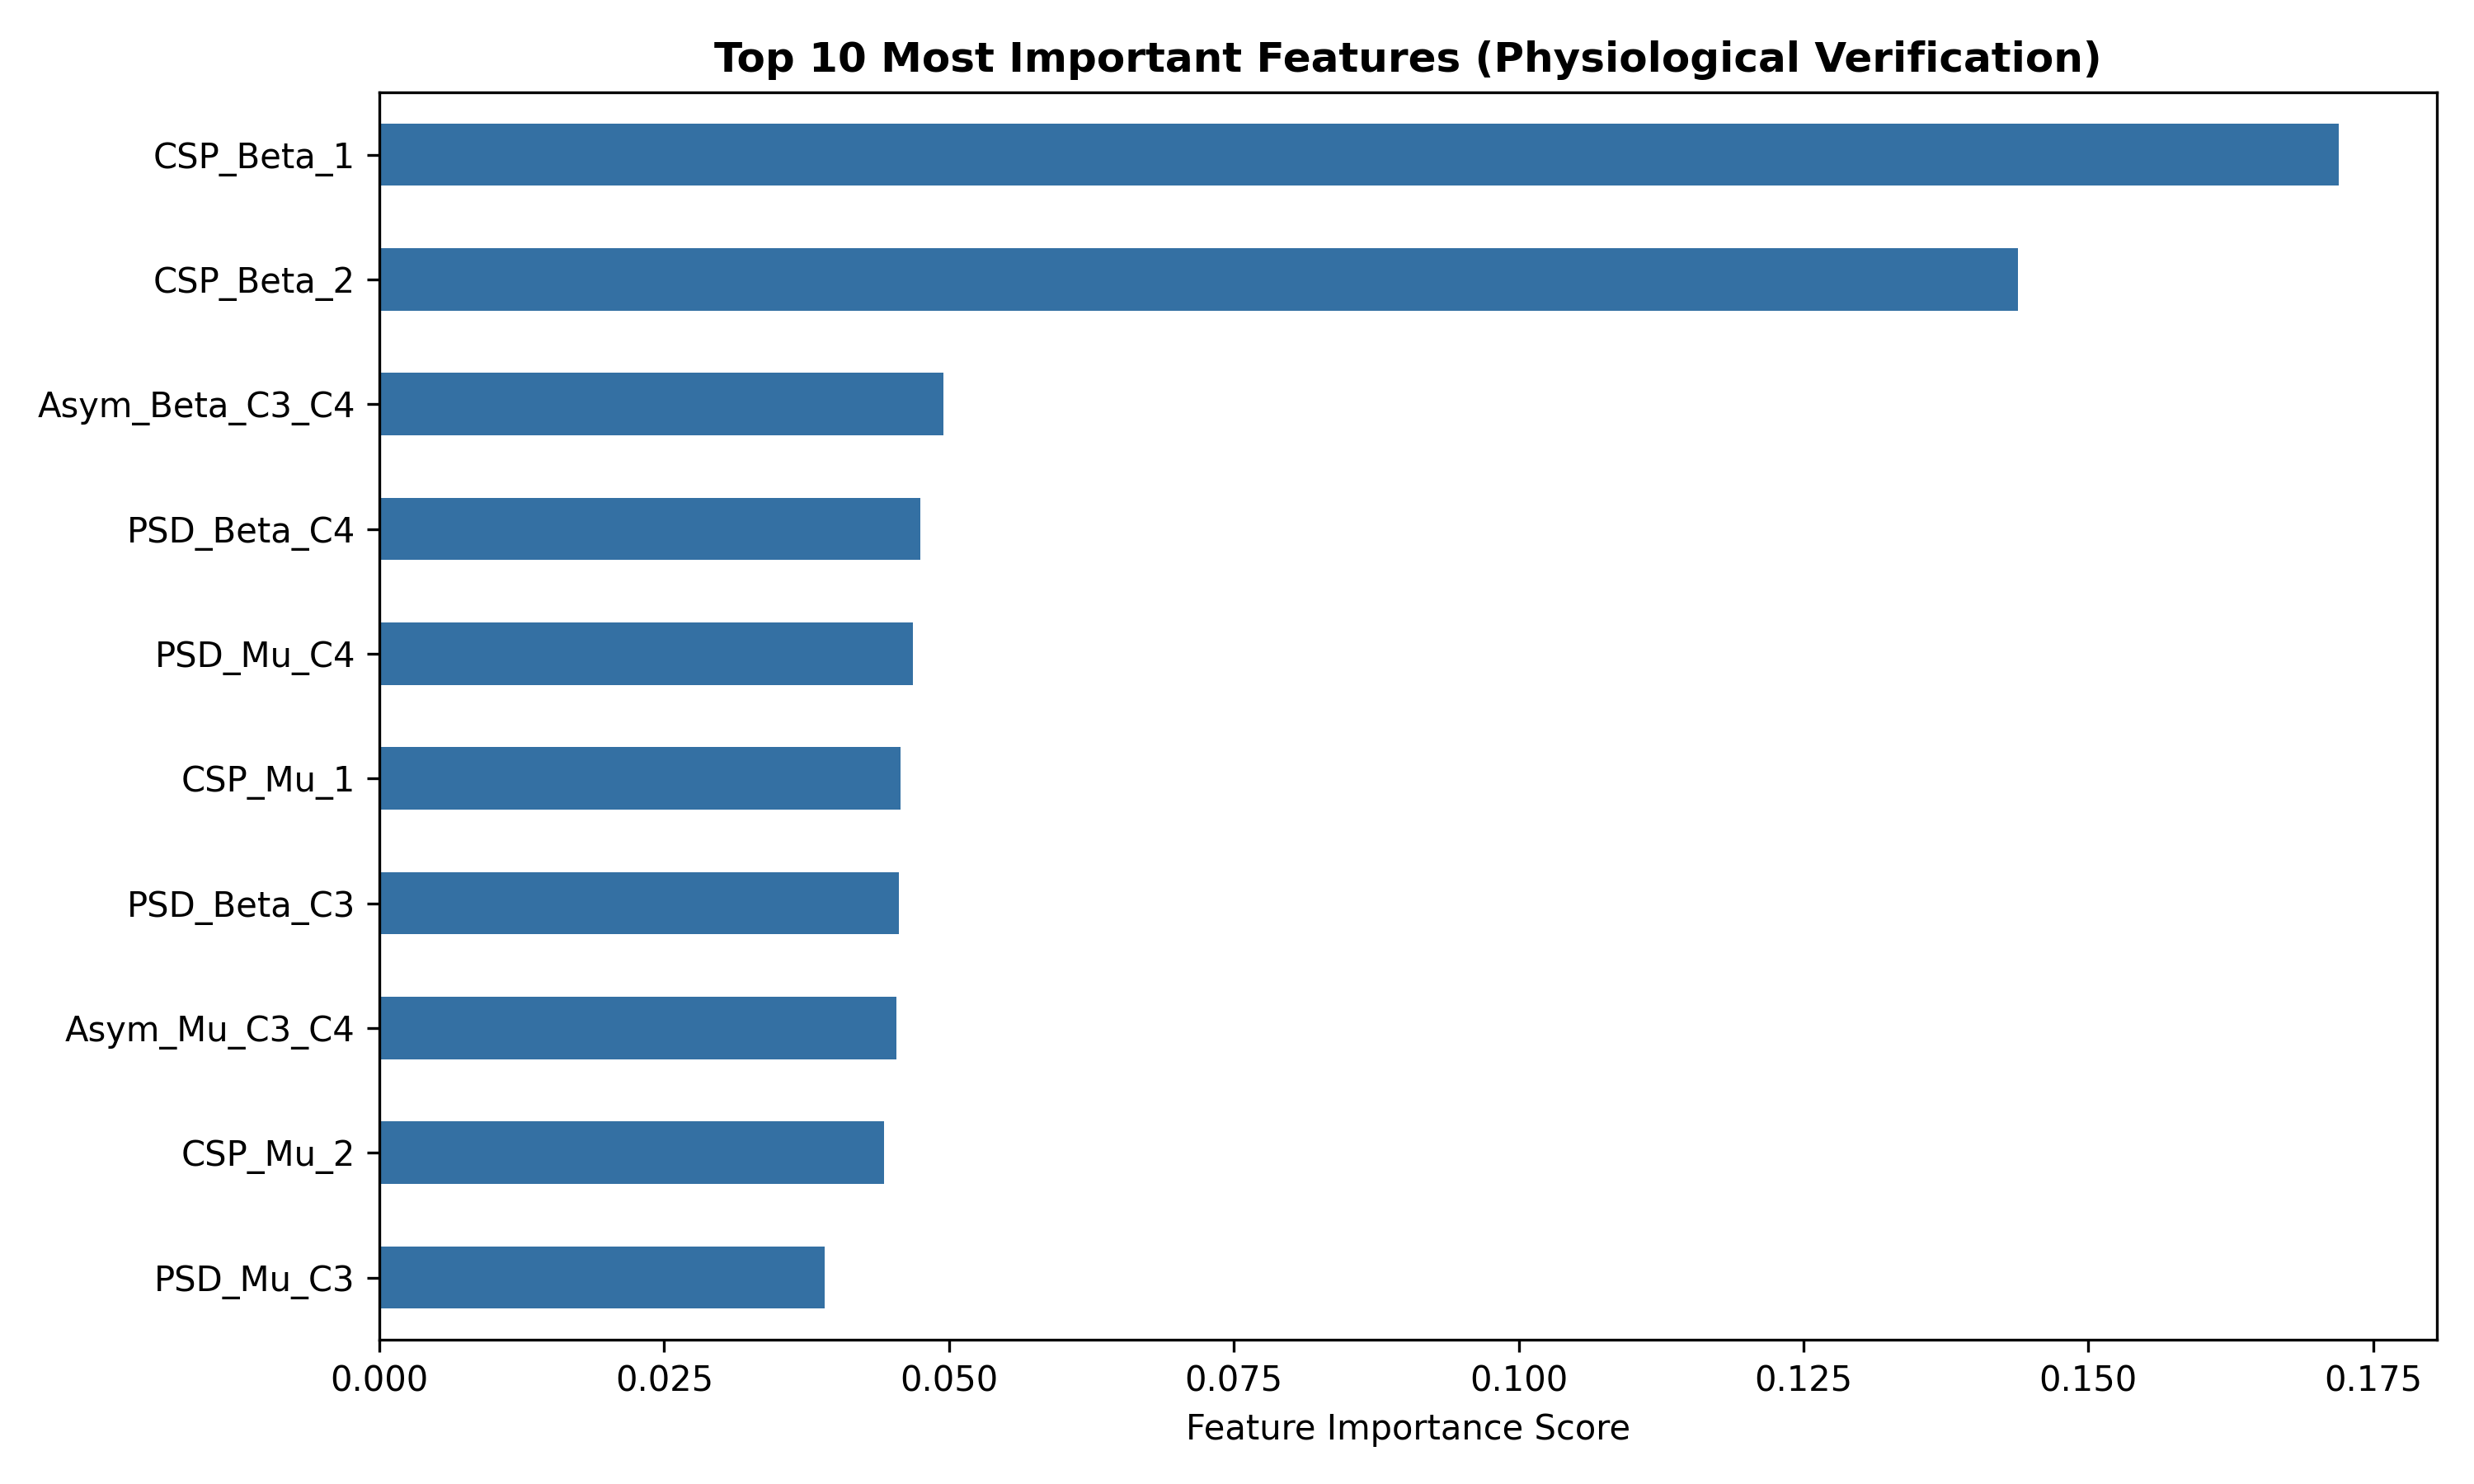

In [8]:
rf_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=SEED)
rf_model.fit(F_train_s, y_train)

feat_imp = pd.Series(rf_model.feature_importances_, index=FEATURE_NAMES).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
feat_imp.head(10).plot(kind="barh", color="#3470a3").invert_yaxis()
plt.title("Top 10 Most Important Features (Neurophysiological Validation)", fontsize=12, fontweight="bold")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.show()

# Serialize pipelines
classical_bundle = {
    "csp_mu": full_csp_m,
    "csp_beta": full_csp_b,
    "scaler": scaler_full,
    "model": best_svm,
    "channels": CHANNELS,
    "feature_names": FEATURE_NAMES
}
joblib.dump(classical_bundle, os.path.join(MODELS_DIR, "best_classical_pipeline.joblib"))
torch.save(final_dl.state_dict(), os.path.join(MODELS_DIR, "best_deep_model.pt"))

print("Export completed successfully!")
print("1. models/best_classical_pipeline.joblib")
print("2. models/best_deep_model.pt")
print("3. models/leaderboard.csv")
print("4. models/test_metrics.json")
